In [1]:
from google.colab import files
import os

os.makedirs("/content/data", exist_ok=True)

uploaded = files.upload()

Saving features.csv to features.csv
Saving stores.csv to stores.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


In [2]:
import os

data_path = "/content/data"

print("Current files:")
print(os.listdir("/content"))

Current files:
['.config', 'train.csv', 'stores.csv', 'test.csv', 'data', 'features.csv', 'sample_data']


In [3]:
import os
import shutil

data_path = "/content/data"
os.makedirs(data_path, exist_ok=True)

for filename in [
    "train.csv",
    "test.csv",
    "features.csv",
    "stores.csv"
]:
    source = f"/content/{filename}"
    destination = f"{data_path}/{filename}"

    if os.path.exists(source):
        shutil.move(source, destination)

print("Dataset files:")
print(os.listdir(data_path))

Dataset files:
['train.csv', 'stores.csv', 'test.csv', 'features.csv']


In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
data_path = "/content/data"

train = pd.read_csv(f"{data_path}/train.csv")
test = pd.read_csv(f"{data_path}/test.csv")
features = pd.read_csv(f"{data_path}/features.csv")
stores = pd.read_csv(f"{data_path}/stores.csv")

print("All datasets loaded successfully!")

print("Training data:", train.shape)
print("Testing data:", test.shape)
print("Features data:", features.shape)
print("Stores data:", stores.shape)

All datasets loaded successfully!
Training data: (421570, 5)
Testing data: (115064, 4)
Features data: (8190, 12)
Stores data: (45, 3)


In [7]:
print("First five rows:")
display(train.head())

print("\nColumn names:")
print(train.columns.tolist())

print("\nDataset information:")
train.info()

print("\nSummary statistics:")
display(train.describe())

First five rows:


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False



Column names:
['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB

Summary statistics:


,Store,Dept,Weekly_Sales
count,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123
std,12.785297,30.492054,22711.183519
min,1.000000,1.000000,-4988.940000
25%,11.000000,18.000000,2079.650000
50%,22.000000,37.000000,7612.030000
75%,33.000000,74.000000,20205.852500
max,45.000000,99.000000,693099.360000


In [8]:
print("Missing values in training data:")
display(train.isnull().sum())

print("\nMissing values in features:")
display(features.isnull().sum())

print("\nMissing values in stores:")
display(stores.isnull().sum())

Missing values in training data:


,0
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0



Missing values in features:


,0
Store,0
Date,0
Temperature,0
Fuel_Price,0
MarkDown1,4158
MarkDown2,5269
MarkDown3,4577
MarkDown4,4726
MarkDown5,4140
CPI,585



Missing values in stores:


,0
Store,0
Type,0
Size,0


In [9]:
print("Missing values in training data:")
display(train.isnull().sum())

print("\nMissing values in features:")
display(features.isnull().sum())

print("\nMissing values in stores:")
display(stores.isnull().sum())

Missing values in training data:


,0
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0



Missing values in features:


,0
Store,0
Date,0
Temperature,0
Fuel_Price,0
MarkDown1,4158
MarkDown2,5269
MarkDown3,4577
MarkDown4,4726
MarkDown5,4140
CPI,585



Missing values in stores:


,0
Store,0
Type,0
Size,0


In [10]:
# Create working copies
train_clean = train.copy()
test_clean = test.copy()
features_clean = features.copy()
stores_clean = stores.copy()

# Convert dates
train_clean["Date"] = pd.to_datetime(train_clean["Date"])
test_clean["Date"] = pd.to_datetime(test_clean["Date"])
features_clean["Date"] = pd.to_datetime(features_clean["Date"])

# Merge store information
train_clean = train_clean.merge(
    stores_clean,
    on="Store",
    how="left"
)

test_clean = test_clean.merge(
    stores_clean,
    on="Store",
    how="left"
)

# Remove duplicate holiday column from features before merging
features_for_merge = features_clean.drop(
    columns=["IsHoliday"],
    errors="ignore"
)

# Merge weekly features
train_clean = train_clean.merge(
    features_for_merge,
    on=["Store", "Date"],
    how="left"
)

test_clean = test_clean.merge(
    features_for_merge,
    on=["Store", "Date"],
    how="left"
)

print("Data merging completed!")

print("Training data shape:", train_clean.shape)
print("Testing data shape:", test_clean.shape)

display(train_clean.head())

Data merging completed!
Training data shape: (421570, 16)
Testing data shape: (115064, 15)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106


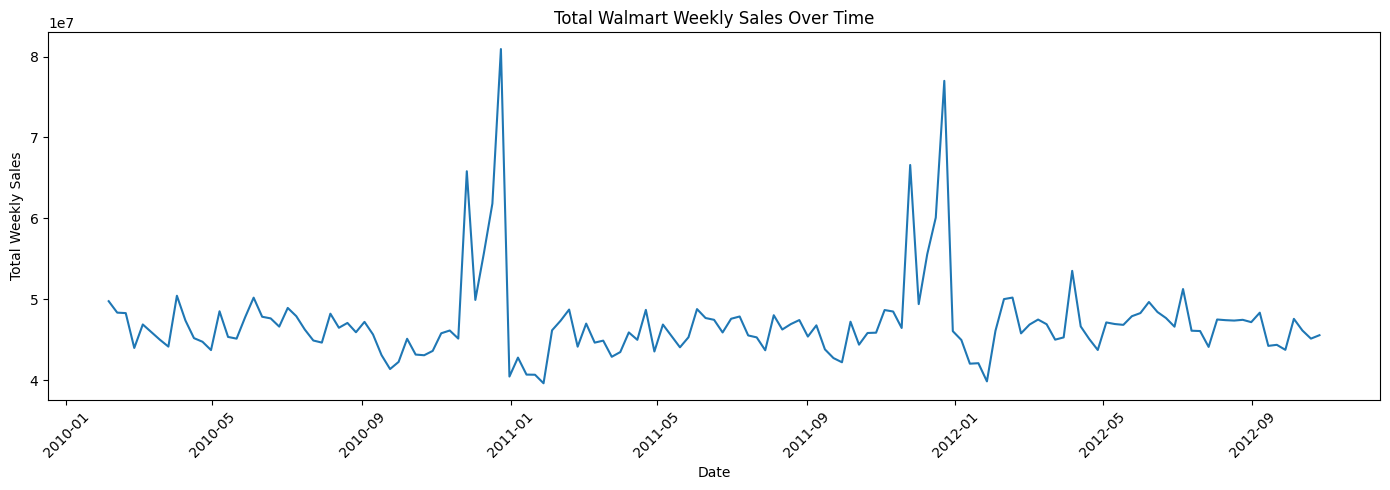

In [11]:
weekly_sales = (
    train_clean.groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title("Total Walmart Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

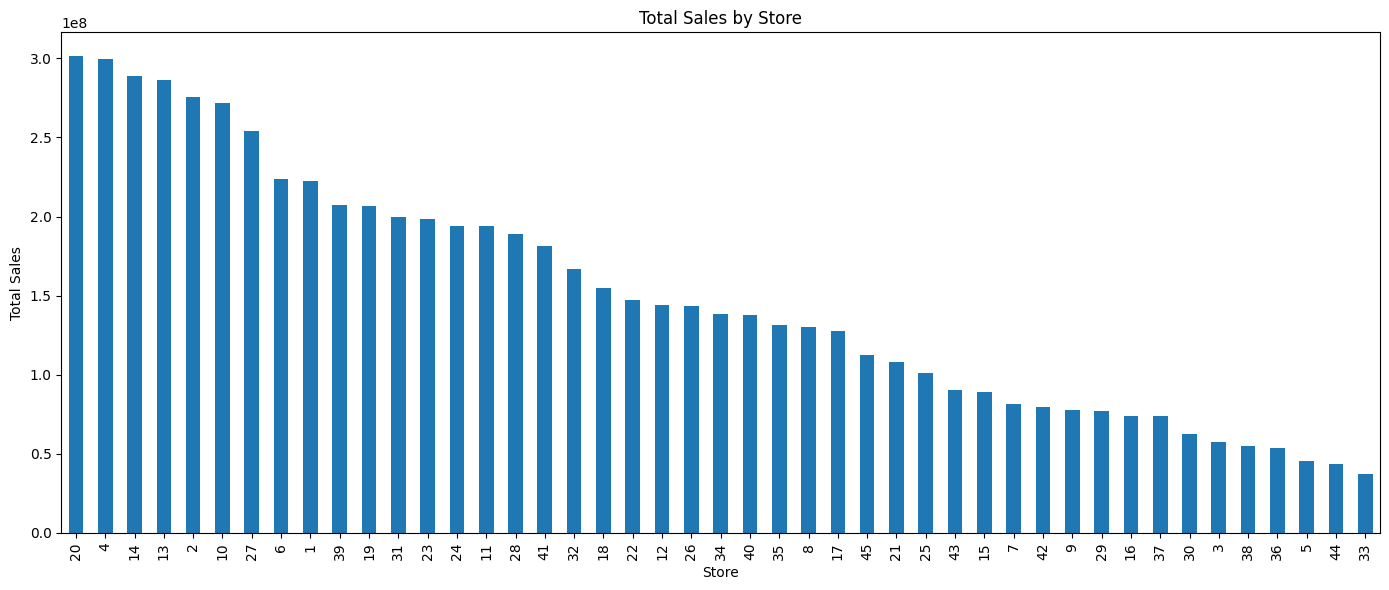

In [12]:
store_sales = (
    train_clean.groupby("Store")["Weekly_Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
store_sales.plot(kind="bar")

plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

Average weekly sales by holiday status:


,Weekly_Sales
IsHoliday,
False,15901.445069
True,17035.823187


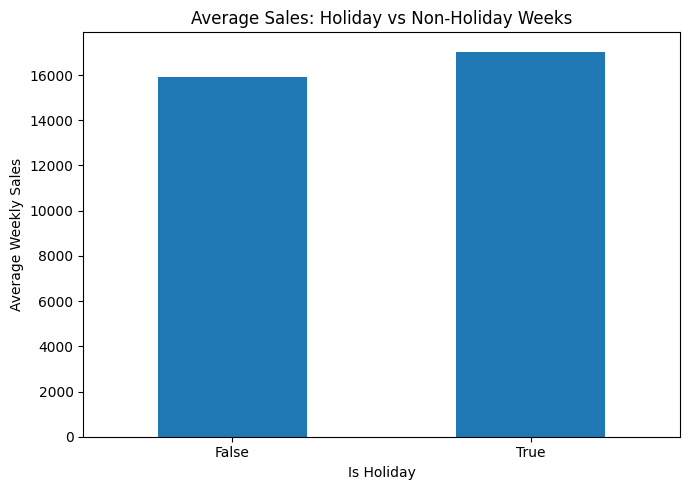

In [13]:
holiday_sales = (
    train_clean.groupby("IsHoliday")["Weekly_Sales"]
    .mean()
)

print("Average weekly sales by holiday status:")
display(holiday_sales)

plt.figure(figsize=(7, 5))
holiday_sales.plot(kind="bar")

plt.title("Average Sales: Holiday vs Non-Holiday Weeks")
plt.xlabel("Is Holiday")
plt.ylabel("Average Weekly Sales")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
def add_date_features(df):
    df = df.copy()

    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

    return df

train_clean = add_date_features(train_clean)
test_clean = add_date_features(test_clean)

print("Date features created successfully!")

display(train_clean.head())

Date features created successfully!


,Store,Dept,Date,Weekly_Sales,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Year,Month,Week
0,1,1,2010-02-05,24924.50,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,2010,2,5
1,1,1,2010-02-12,46039.49,True,A,151315,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,2010,2,6
2,1,1,2010-02-19,41595.55,False,A,151315,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,2010,2,7
3,1,1,2010-02-26,19403.54,False,A,151315,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,2010,2,8
4,1,1,2010-03-05,21827.90,False,A,151315,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,2010,3,9


In [15]:
target = "Weekly_Sales"

candidate_features = [
    "Store",
    "Dept",
    "IsHoliday",
    "Type",
    "Size",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Week"
]

available_features = [
    col for col in candidate_features
    if col in train_clean.columns and col in test_clean.columns
]

print("Selected features:")
print(available_features)

Selected features:
['Store', 'Dept', 'IsHoliday', 'Type', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Year', 'Month', 'Week']


In [16]:
# Step 17: Prepare data for machine learning

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Sort the dataset by date
train_clean = train_clean.sort_values("Date").reset_index(drop=True)

# Define target and input features
target = "Weekly_Sales"

candidate_features = [
    "Store",
    "Dept",
    "IsHoliday",
    "Type",
    "Size",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Year",
    "Month",
    "Week"
]

# Use only columns available in both datasets
features_used = [
    col for col in candidate_features
    if col in train_clean.columns and col in test_clean.columns
]

# Define X and y
X = train_clean[features_used].copy()
y = train_clean[target].copy()

# Identify categorical and numerical columns
categorical_features = X.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Total records:", len(X))
print("Total features:", len(features_used))
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

display(X.head())

Total records: 421570
Total features: 17
Categorical features: ['IsHoliday', 'Type']
Numerical features: ['Store', 'Dept', 'Size', 'Temperature', 'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'CPI', 'Unemployment', 'Year', 'Month', 'Week']


,Store,Dept,IsHoliday,Type,Size,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Year,Month,Week
0,1,1,False,A,151315,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,2010,2,5
1,29,5,False,B,93638,24.36,2.788,NaN,NaN,NaN,NaN,NaN,131.527903,10.064,2010,2,5
2,29,6,False,B,93638,24.36,2.788,NaN,NaN,NaN,NaN,NaN,131.527903,10.064,2010,2,5
3,29,7,False,B,93638,24.36,2.788,NaN,NaN,NaN,NaN,NaN,131.527903,10.064,2010,2,5
4,29,8,False,B,93638,24.36,2.788,NaN,NaN,NaN,NaN,NaN,131.527903,10.064,2010,2,5


In [17]:
# Step 18: Chronological train-validation split

split_index = int(len(train_clean) * 0.80)

X_train = X.iloc[:split_index].copy()
X_val = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_val = y.iloc[split_index:].copy()

print("Training records:", len(X_train))
print("Validation records:", len(X_val))

print(
    "Training date range:",
    train_clean.iloc[:split_index]["Date"].min(),
    "to",
    train_clean.iloc[:split_index]["Date"].max()
)

print(
    "Validation date range:",
    train_clean.iloc[split_index:]["Date"].min(),
    "to",
    train_clean.iloc[split_index:]["Date"].max()
)

Training records: 337256
Validation records: 84314
Training date range: 2010-02-05 00:00:00 to 2012-04-13 00:00:00
Validation date range: 2012-04-13 00:00:00 to 2012-10-26 00:00:00


In [18]:
# Step 19: Preprocessing pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
# Step 20: Linear Regression model

from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)

print("Linear Regression training completed!")
print("Sample predictions:", linear_predictions[:10])

Linear Regression training completed!
Sample predictions: [11923.45376658 27711.65659101 17406.93740553  5185.4933017
 22648.14275244 11945.80100744 12524.1402289   6925.21475131
  8010.74324509 22468.3887464 ]


In [20]:
# Step 21: Random Forest model

from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_val)

print("Random Forest training completed!")
print("Sample predictions:", rf_predictions[:10])

Random Forest training completed!
Sample predictions: [3.57858106e+04 7.73502801e+04 2.86304883e+04 2.34406042e+03
 8.88746970e+03 1.10052341e+04 1.43112630e+04 2.16562480e+01
 2.81333883e+03 2.85000125e+03]


In [21]:
# Step 22: Model evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame([
    evaluate_model(
        "Linear Regression",
        y_val,
        linear_predictions
    ),
    evaluate_model(
        "Random Forest",
        y_val,
        rf_predictions
    )
])

display(results.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,14477.320,20877.373,0.095
1,Random Forest,1846.801,3819.327,0.970


In [22]:
results.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


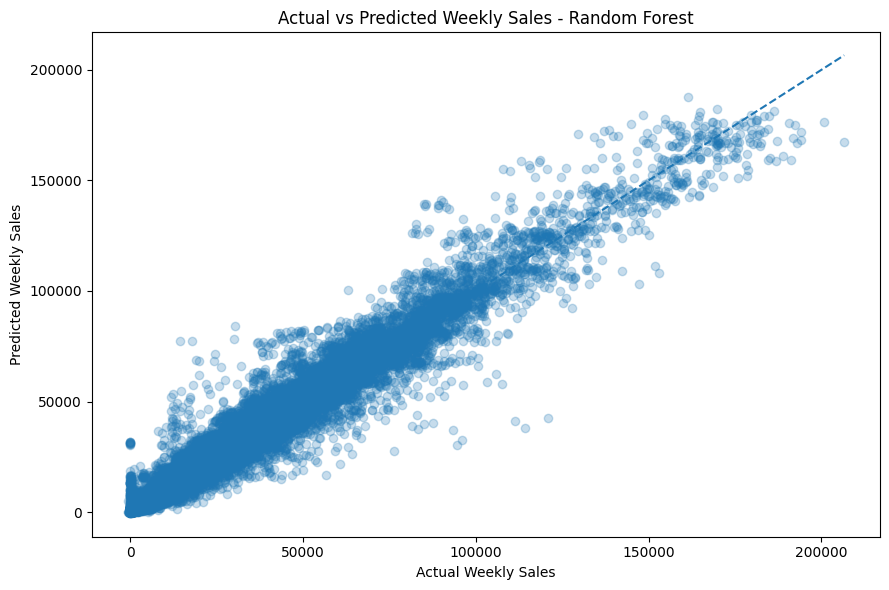

In [23]:
# Step 23: Actual vs predicted sales

plt.figure(figsize=(9, 6))

plt.scatter(
    y_val,
    rf_predictions,
    alpha=0.25
)

min_value = min(y_val.min(), rf_predictions.min())
max_value = max(y_val.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Weekly Sales - Random Forest")
plt.xlabel("Actual Weekly Sales")
plt.ylabel("Predicted Weekly Sales")

plt.tight_layout()
plt.show()

In [24]:
# Step 24: Select the model using validation MAE

model_candidates = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

best_model_name = results.loc[
    results["MAE"].idxmin(),
    "Model"
]

best_model = model_candidates[best_model_name]

print("Selected model:", best_model_name)

print(
    "Validation MAE:",
    results.loc[
        results["Model"] == best_model_name,
        "MAE"
    ].iloc[0]
)

Selected model: Random Forest
Validation MAE: 1846.8007326034776


In [25]:
# Step 25: Predict sales for test.csv

X_test = test_clean[features_used].copy()

test_predictions = best_model.predict(X_test)

prediction_output = test_clean[
    ["Store", "Dept", "Date", "IsHoliday"]
].copy()

prediction_output["Predicted_Weekly_Sales"] = test_predictions

prediction_output.to_csv(
    "/content/predicted_sales.csv",
    index=False
)

print("Sales predictions generated successfully!")

display(prediction_output.head(10))

print(
    "Prediction file saved to:",
    "/content/predicted_sales.csv"
)

Sales predictions generated successfully!


,Store,Dept,Date,IsHoliday,Predicted_Weekly_Sales
0,1,1,2012-11-02,False,32220.180987
1,1,1,2012-11-09,False,19077.993356
2,1,1,2012-11-16,False,18911.213398
3,1,1,2012-11-23,True,19870.591978
4,1,1,2012-11-30,False,20847.595036
5,1,1,2012-12-07,False,41416.391251
6,1,1,2012-12-14,False,40030.091435
7,1,1,2012-12-21,False,48138.932679
8,1,1,2012-12-28,True,19570.921680
9,1,1,2013-01-04,False,18291.839794


Prediction file saved to: /content/predicted_sales.csv


In [26]:
# Step 26: Save the trained model

import joblib

joblib.dump(
    best_model,
    "/content/sales_prediction_model.joblib"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [27]:
display(results.round(3))

,Model,MAE,RMSE,R2
0,Linear Regression,14477.320,20877.373,0.095
1,Random Forest,1846.801,3819.327,0.970


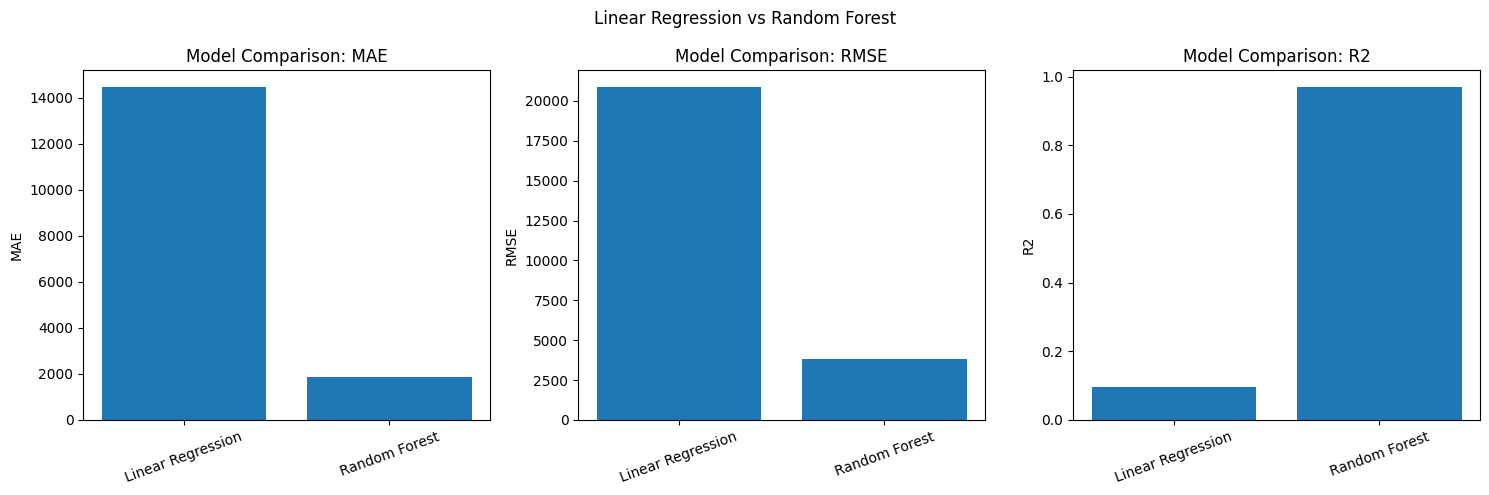

Model comparison chart saved successfully.


In [28]:
import matplotlib.pyplot as plt
import os

os.makedirs("/content/outputs", exist_ok=True)

metrics = ["MAE", "RMSE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    ax.bar(results["Model"], results[metric])
    ax.set_title(f"Model Comparison: {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("Linear Regression vs Random Forest")
plt.tight_layout()

plt.savefig(
    "/content/outputs/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model comparison chart saved successfully.")

In [29]:
from google.colab import files

files.download("/content/model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
files.download("/content/predicted_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
files.download("/content/outputs/model_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>